# Problem 2


### Task a)

In [142]:
#%pip install seaborn

In [143]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy 


In [153]:
#defining a regular 1D grid of parameter values from theta = 0.25 to theta = 0.50
param_grid = np.linspace(0.25, 0.50, 51)

#Evaluation points
eval_points = np.array([0.30, 0.35, 0.39, 0.41, 0.45])

#rounding to avoid 
grid = np.setdiff1d(np.round(param_grid, 3), np.round(eval_points, 3 ))

#Expected value, varians and Corr
exp_value = 0.5
varians = 0.5**2

def corr(theta_1, theta_2):
    return (1 + 15 * np.abs(theta_1 - theta_2)) * np.exp(-15 * np.abs(theta_1 - theta_2))

#Computing the covariance from the correlation formula given in the task and the variance
def cov(theta_1, theta_2):
    return corr(theta_1, theta_2)*varians

#Constructing the mean vector
mean_vec = np.full(46, exp_value)
mean_vec_e = np.full(5, exp_value)

#Constructing the covariance matrix
def cov_matrix(rows, columns):
    matrix = np.zeros((len(rows), len(columns)))
    for j in range(len(columns)):
        for i in range(len(rows)):
            matrix[i][j] = cov(columns[j], rows[i])
            

    return matrix

#Computing the three matrices
eval_cov_matrix = cov_matrix(eval_points, eval_points)
grid_eval_cov_matrix= cov_matrix(grid, eval_points)
eval_grid_cov_matrix= cov_matrix( eval_points, grid)
grid_cov_matrix= cov_matrix(grid, grid)

print(eval_cov_matrix)
print(grid_eval_cov_matrix)
print(np.linalg.inv(eval_cov_matrix))


[[0.25       0.20666037 0.15230365 0.12723306 0.08563687]
 [0.20666037 0.25       0.21952465 0.19312059 0.13945635]
 [0.15230365 0.21952465 0.25       0.24076592 0.19312059]
 [0.12723306 0.19312059 0.24076592 0.25       0.21952465]
 [0.08563687 0.13945635 0.19312059 0.21952465 0.25      ]]
[[0.20666037 0.13945635 0.09490373 0.07711026 0.04978707]
 [0.21320925 0.14580826 0.09982034 0.08128249 0.05265848]
 [0.21952465 0.15230365 0.10492713 0.08563687 0.05567516]
 [0.22553048 0.15892636 0.11022388 0.09017647 0.05884232]
 [0.2311402  0.16565682 0.11570922 0.09490373 0.0621651 ]
 [0.23625569 0.17247162 0.12138039 0.09982034 0.06564853]
 [0.24076592 0.1793431  0.12723306 0.10492713 0.06929748]
 [0.24454559 0.18623872 0.13326111 0.11022388 0.0731166 ]
 [0.24745354 0.19312059 0.13945635 0.11570922 0.07711026]
 [0.24933106 0.19994472 0.14580826 0.12138039 0.08128249]
 [0.24933106 0.21320925 0.15892636 0.13326111 0.09017647]
 [0.24745354 0.21952465 0.16565682 0.13945635 0.09490373]
 [0.24454559 

### Printing the matrices

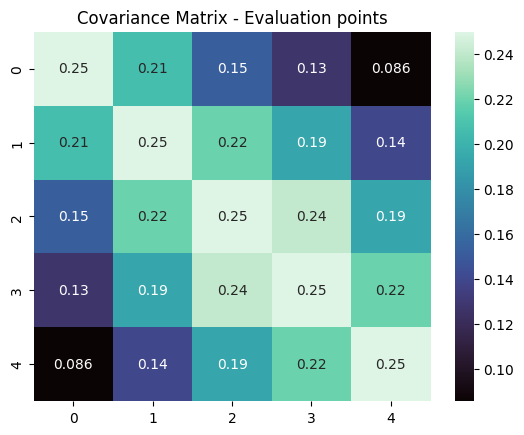

"#51x51 - Paramater grid\nplt.figure(figsize=(10,10))\nsns.heatmap(grid_cov_matrix, cmap ='crest', annot = True)\nplt.title('Covariance Matrix - Evaluation points')\nplt.show()"

In [154]:
#Printing the matrices
#5x5 - EValuation points
sns.heatmap(eval_cov_matrix, cmap ='mako', annot = True)
plt.title('Covariance Matrix - Evaluation points')
plt.show()

"""#51x5 - Parameter grid x Evaluation Points
plt.figure(figsize=(10,10))
sns.heatmap(grid_eval_cov_matrix, cmap ='flare', annot = True)
plt.title('Covariance Matrix - Evaluation points')
plt.show()"""

"""#51x51 - Paramater grid
plt.figure(figsize=(10,10))
sns.heatmap(grid_cov_matrix, cmap ='crest', annot = True)
plt.title('Covariance Matrix - Evaluation points')
plt.show()"""

In [155]:
#Computing the conditional mean and the covariance matrix

y = np.array([0.5, 0.32, 0.40, 0.35, 0.6])
cond_mean = mean_vec + grid_eval_cov_matrix@np.linalg.inv(eval_cov_matrix)@(y-mean_vec_e)


covariance_matrix = grid_cov_matrix - grid_eval_cov_matrix@np.linalg.inv(eval_cov_matrix)@eval_grid_cov_matrix


In [156]:
#Checking for negative variances -> due to computational error
diagonal = np.diag(covariance_matrix)

print("Minimum variance:", np.min(diagonal))
print("Maximum variance:", np.max(diagonal))
print("Number of negative variances:", np.sum(diagonal < 0))

Minimum variance: 0.0001995104651660029
Maximum variance: 0.06584100612394514
Number of negative variances: 0


In [158]:
#Computing lower and upper bound for the prediciton interval
Lower = []
Upper = []
std = np.sqrt(np.diag(covariance_matrix))

for i in range(len(grid)):
    Lower.append(cond_mean[i] - scipy.stats.norm.ppf(0.95)*std[i])
    
    Upper.append(cond_mean[i] + scipy.stats.norm.ppf(0.95)*std[i])
    




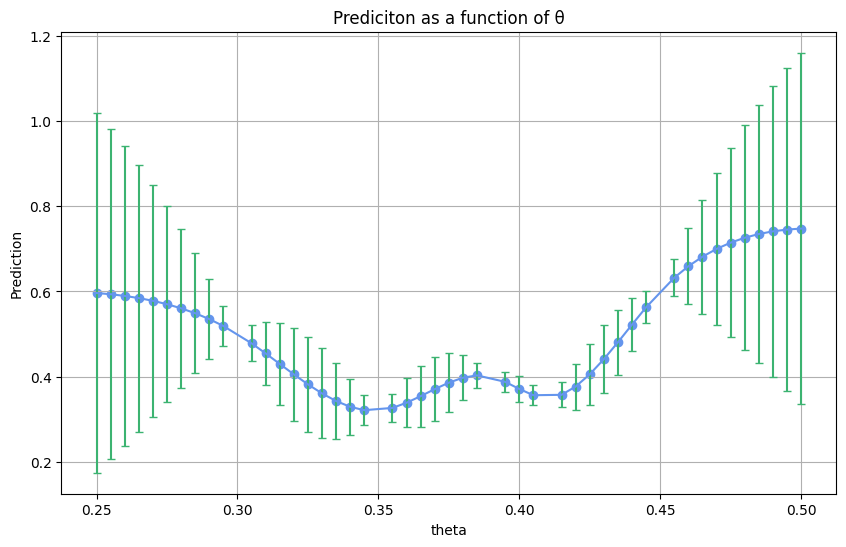

In [160]:
#plotting the result
plt.figure(figsize=(10, 6))
plt.scatter(grid, cond_mean, color = 'cornflowerblue')
plt.errorbar(grid, cond_mean, yerr=[cond_mean-Lower, Upper- cond_mean], color = 'cornflowerblue', ecolor='mediumseagreen', capsize=3)
plt.xlabel('theta')
plt.ylabel('Prediction')
plt.title('Prediciton as a function of θ')
plt.grid(True)
plt.show()


### Task b)

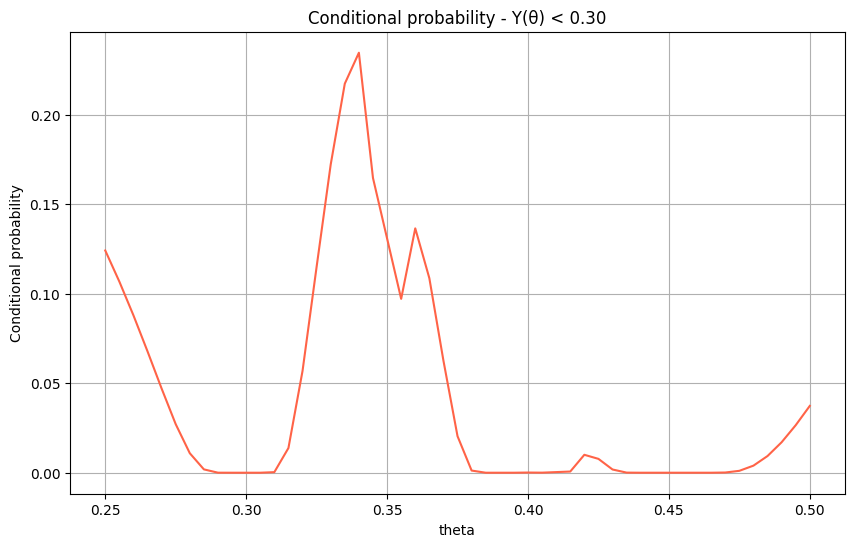

In [164]:
#Defining the cululative distribution function of the standard Gaussian pdf
cond_prob = []

for i in range(len(grid)):
    cond_prob.append(scipy.stats.norm.cdf((0.30-cond_mean[i])/(std[i])))

plt.figure(figsize=(10,6))
plt.plot(grid, cond_prob, color='tomato')
plt.title('Conditional probability - Y(θ) < 0.30')
plt.xlabel('theta')
plt.ylabel('Conditional probability')   
plt.grid(True)
plt.show()

### Task c)

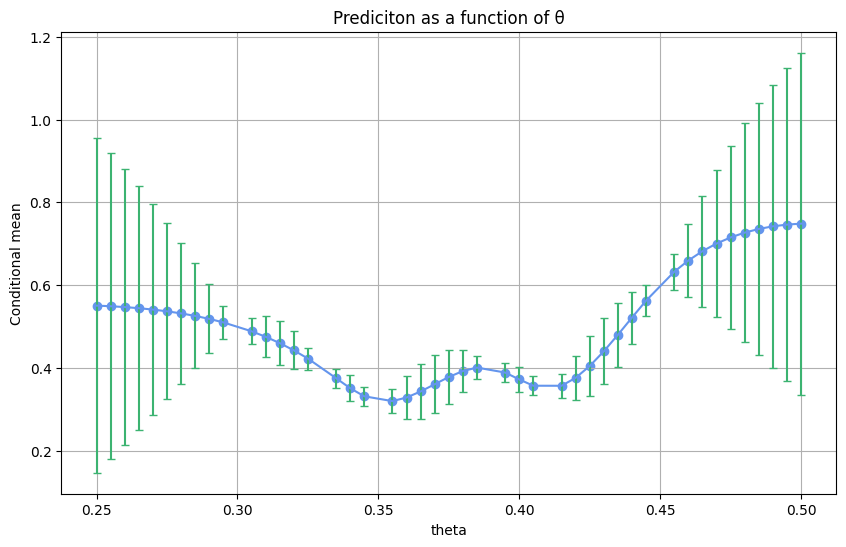

19
0.36


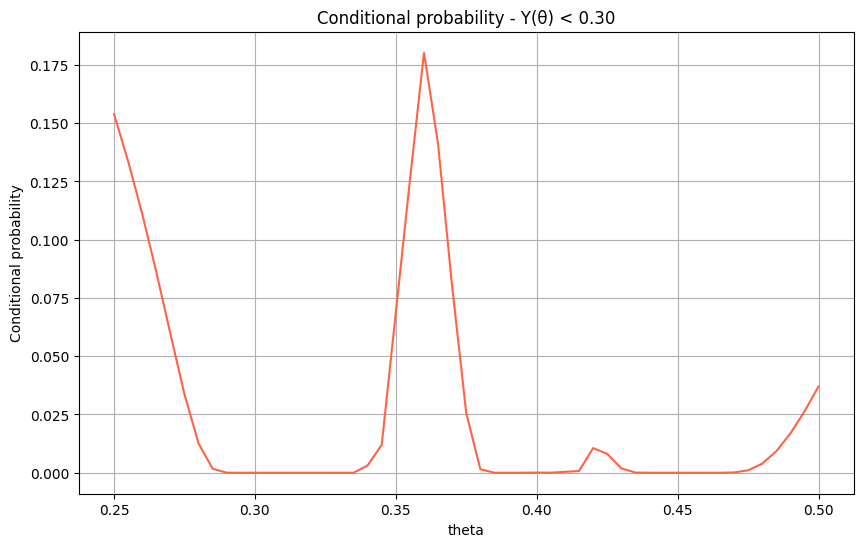

In [ ]:
#Computing the covariance matrix and cond_exp with the new evaluation point added
eval_points = np.array([0.30, 0.33, 0.35, 0.39, 0.41, 0.45])
y = np.array([0.5, 0.40, 0.32, 0.40, 0.35, 0.6])

grid = np.setdiff1d(np.round(param_grid, 3), np.round(eval_points, 3 ))

mean_vec = np.full(45, exp_value)
mean_vec_e = np.full(6, exp_value)

eval_cov_matrix = cov_matrix(eval_points, eval_points)
grid_eval_cov_matrix= cov_matrix(grid, eval_points)
eval_grid_cov_matrix= cov_matrix( eval_points, grid)
grid_cov_matrix= cov_matrix(grid, grid)

cond_mean = mean_vec + grid_eval_cov_matrix@np.linalg.inv(eval_cov_matrix)@(y-mean_vec_e)
covariance_matrix = grid_cov_matrix - grid_eval_cov_matrix@np.linalg.inv(eval_cov_matrix)@eval_grid_cov_matrix
std = np.sqrt(np.diag(covariance_matrix))

#Computing lower and upper bound for the prediciton interval
Lower = []
Upper = []

for i in range(len(grid)):
    Lower.append(cond_mean[i] - scipy.stats.norm.ppf(0.95)*std[i])
    
    Upper.append(cond_mean[i] + scipy.stats.norm.ppf(0.95)*std[i])

#plotting the prediciton as a fucntion of theta
plt.figure(figsize=(10, 6))
plt.scatter(grid, cond_mean, color = 'cornflowerblue')
plt.errorbar(grid, cond_mean, yerr=[cond_mean-Lower, Upper- cond_mean], color = 'cornflowerblue', ecolor='mediumseagreen', capsize=3)
plt.xlabel('theta')
plt.ylabel('Conditional mean')
plt.title('Prediciton as a function of θ')
plt.grid(True)
plt.show()


cond_prob = []

for i in range(len(grid)):
    cond_prob.append(scipy.stats.norm.cdf((0.30-cond_mean[i])/((std[i]))))


print(cond_prob.index(max(cond_prob)))
print(grid[cond_prob.index(max(cond_prob))])

#Plotting the conditional probability
plt.figure(figsize=(10,6))
plt.plot(grid, cond_prob, color='tomato')
plt.title('Conditional probability - Y(θ) < 0.30')
plt.xlabel('theta')
plt.ylabel('Conditional probability')   
plt.grid(True)
plt.show()

